# Tutorial 71: Time Curves

This example demonstrates how to obtain necessary data and plot time curves.

# SIR 3S Installation

In [1]:
SIR3S_SIRGRAF_DIR = r"C:\3S\SIR 3S\SirGraf-90-15-00-24_Quebec-Upd2" #change to local path

# Imports

In [2]:
from sir3stoolkit.core import wrapper

In [3]:
from sir3stoolkit.mantle import mantle

The wrapper package has to be initialized with reference to a SIR 3S (SirGraf) installation.

In [4]:
wrapper.Initialize_Toolkit(SIR3S_SIRGRAF_DIR)

[2026-11-25 16:27:08,441] INFO in sir3stoolkit.core.wrapper: [Initialization] Using provided SirGraf path: C:\3S\SIR 3S\SirGraf-90-15-00-24_Quebec-Upd2


[2026-11-25 16:27:08,441] INFO in sir3stoolkit.core.wrapper: [Initialization] Using provided SirGraf path: C:\3S\SIR 3S\SirGraf-90-15-00-24_Quebec-Upd2


[2026-11-25 16:27:08,470] INFO in sir3stoolkit.core.wrapper: [Initialization] Initializing toolkit with SirGraf path: C:\3S\SIR 3S\SirGraf-90-15-00-24_Quebec-Upd2


[2026-11-25 16:27:08,592] INFO in sir3stoolkit.core.wrapper: [Initialization] Sir3S_Toolkit.dll file version 90.15.11.0 (matches this sir3stoolkit version).


## Additional imports

In [5]:
import pandas as pd

...

# Initialization

In [6]:
s3s = mantle.SIR3S_Model_Mantle()

[2026-11-25 16:27:08,753] INFO in sir3stoolkit.core.wrapper: [Model Class Initialization] Initialization complete


# Open Model

The tutorial uses *Network 3*, a fictional district heating network shared by the mantle tutorials: a heat plant (in its own container "Heizwerk"), about 180 consumers, a ring road and two longitudinal sections, calculated over one day. It is built from scratch with the SIR 3S Toolkit by [Network3.py](https://github.com/3SConsult/sir3stoolkit/blob/main/docs/source/networks/Network3.py); `Network3.db3` is included in the tutorial's ZIP archive.

Its elements have unique ID references (IDREFERENZ), e.g. `VL-HS-01` for the first supply pipe of the main street. They are used below to look up tks with [GetTkFromIDReference()](https://3sconsult.github.io/sir3stoolkit/references/sir3stoolkit.core.html#sir3stoolkit.core.wrapper.SIR3S_Model.GetTkFromIDReference) - the tks themselves differ between builds of the model.

In [7]:
dbFilePath=r"Network3.db3"

In [8]:
s3s.OpenModel(dbName=dbFilePath,
              providerType=s3s.ProviderTypes.SQLite,
              Mid="M-1-0-1",
              saveCurrentlyOpenModel=False,
              namedInstance="",
              userID="",
              password="")

[2026-11-25 16:27:13,921] INFO in sir3stoolkit.core.wrapper: Model is open for further operation


# Calculate Model

In [9]:
s3s.ExecCalculation(True) # To ensure result data

[2026-11-25 16:27:20,106] INFO in sir3stoolkit.core.wrapper: Model Calculation is complete


# Obtain Data

In [10]:
object_types = [item for item in dir(s3s.ObjectTypes) if not (item.startswith('__') and item.endswith('__'))]
print(object_types)

['AGSN_HydraulicProfile', 'AirVessel', 'Arrow', 'Atmosphere', 'BlockConnectionNode', 'CalcPari', 'CharacteristicLossTable', 'CharacteristicLossTable_Row', 'Circle', 'Compressor', 'CompressorTable', 'CompressorTable_Row', 'ControlEngineeringNexus', 'ControlMode', 'ControlPointTable', 'ControlPointTable_Row', 'ControlValve', 'ControlVariableConverter', 'ControlVariableConverterRSTE', 'CrossSectionTable', 'CrossSectionTable_Row', 'DPGR_DPKT_DatapointDpgrConnection', 'DPGR_DataPointGroup', 'DPKT_Datapoint', 'DamageRatesTable', 'DamageRatesTable_Row', 'DeadTimeElement', 'Demand', 'DifferentialRegulator', 'DirectionalArrow', 'DistrictHeatingConsumer', 'DistrictHeatingFeeder', 'Divider', 'DriveEfficiencyTable', 'DriveEfficiencyTable_Row', 'DrivePowerTable', 'DrivePowerTable_Row', 'EBES_FeederGroups', 'EfficiencyConverterTable', 'EfficiencyConverterTable_Row', 'ElementQuery', 'EnergyRecoveryTable', 'EnergyRecoveryTable_Row', 'EnvironmentTemp', 'FWBZ_DistrictHeatingReferenceValues', 'FlapValve'

## Nodes

In [11]:
# supply and return of the heat plant and of the hospital (the end of the main street)
nodes_tks = [s3s.GetTkFromIDReference(id_ref, s3s.ObjectTypes.Node) for id_ref in ["V-HW", "R-HW", "V-H-KRANKENHAUS", "R-H-KRANKENHAUS"]]

In [12]:
df_nodes_results = s3s.generate_element_results_dataframe(element_type=s3s.ObjectTypes.Node
                                                          ,tks=nodes_tks
                                                          ,properties=["PH"]
                                                          ,timestamps=None # all available simulation timestamps will be used
                                                          )

[2026-11-25 16:27:20,177] INFO in sir3stoolkit.mantle.dataframes: [results] Generating results dataframe for element type: ObjectTypes.Node


[2026-11-25 16:27:20,619] INFO in sir3stoolkit.mantle.dataframes: [Resolving Timestamps] No timestamps were given. Checking available simulation timestamps (SIR3S_Model.GetTimeStamps()[0]).


[2026-11-25 16:27:20,623] INFO in sir3stoolkit.mantle.dataframes: [Resolving Timestamps] 13 simulation timestamp(s) are available.


[2026-11-25 16:27:20,624] INFO in sir3stoolkit.mantle.dataframes: [Resolving Timestamps] Using 13 timestamps: ['2026-01-15 00:00:00.000 +01:00', '2026-01-15 02:00:00.000 +01:00', '2026-01-15 04:00:00.000 +01:00', '2026-01-15 06:00:00.000 +01:00', '2026-01-15 08:00:00.000 +01:00', '2026-01-15 10:00:00.000 +01:00', '2026-01-15 12:00:00.000 +01:00', '2026-01-15 14:00:00.000 +01:00', '2026-01-15 16:00:00.000 +01:00', '2026-01-15 18:00:00.000 +01:00', '2026-01-15 20:00:00.000 +01:00', '2026-01-15 22:00:00.000 +01:00', '2026-01-16 00:00:00.000 +01:00']


[2026-11-25 16:27:20,632] INFO in sir3stoolkit.mantle.dataframes: [Resolving tks] Retrieved 592 element(s) of element type ObjectTypes.Node.


[2026-11-25 16:27:20,634] INFO in sir3stoolkit.mantle.dataframes: [Resolving tks] 4 tks remain after filtering for given tks.


... (4 outputs left out)

[2026-11-25 16:27:20,809] INFO in sir3stoolkit.mantle.dataframes: [results] 0 fully NaN columns dropped.


[2026-11-25 16:27:20,809] INFO in sir3stoolkit.mantle.dataframes: [results] DataFrame assembled (0.0 s).


[2026-11-25 16:27:20,843] INFO in sir3stoolkit.mantle.dataframes: [results] Names/end nodes of 4 element(s) looked up (0.0 s).


[2026-11-25 16:27:20,849] INFO in sir3stoolkit.mantle.dataframes: [results] Done. Shape: (13, 4) (0.7 s in total)


## Vents

In [13]:
vent_tks = [s3s.GetTkFromIDReference("KLAPPE-HW", s3s.ObjectTypes.FlapValve)] # non-return valve behind the network pumps

In [14]:
df_vent_results = s3s.generate_element_results_dataframe(element_type=s3s.ObjectTypes.FlapValve
                                                          ,tks=vent_tks
                                                          ,properties=["PHI", "QM"]
                                                          ,timestamps=None # all available simulation timestamps will be used
                                                          )

[2026-11-25 16:27:20,895] INFO in sir3stoolkit.mantle.dataframes: [results] Generating results dataframe for element type: ObjectTypes.FlapValve


[2026-11-25 16:27:21,192] INFO in sir3stoolkit.mantle.dataframes: [Resolving Timestamps] No timestamps were given. Checking available simulation timestamps (SIR3S_Model.GetTimeStamps()[0]).


[2026-11-25 16:27:21,195] INFO in sir3stoolkit.mantle.dataframes: [Resolving Timestamps] 13 simulation timestamp(s) are available.


[2026-11-25 16:27:21,200] INFO in sir3stoolkit.mantle.dataframes: [Resolving Timestamps] Using 13 timestamps: ['2026-01-15 00:00:00.000 +01:00', '2026-01-15 02:00:00.000 +01:00', '2026-01-15 04:00:00.000 +01:00', '2026-01-15 06:00:00.000 +01:00', '2026-01-15 08:00:00.000 +01:00', '2026-01-15 10:00:00.000 +01:00', '2026-01-15 12:00:00.000 +01:00', '2026-01-15 14:00:00.000 +01:00', '2026-01-15 16:00:00.000 +01:00', '2026-01-15 18:00:00.000 +01:00', '2026-01-15 20:00:00.000 +01:00', '2026-01-15 22:00:00.000 +01:00', '2026-01-16 00:00:00.000 +01:00']


[2026-11-25 16:27:21,203] INFO in sir3stoolkit.mantle.dataframes: [Resolving tks] Retrieved 1 element(s) of element type ObjectTypes.FlapValve.


[2026-11-25 16:27:21,207] INFO in sir3stoolkit.mantle.dataframes: [Resolving tks] 1 tks remain after filtering for given tks.


... (4 outputs left out)

[2026-11-25 16:27:21,302] INFO in sir3stoolkit.mantle.dataframes: [results] 0 fully NaN columns dropped.


[2026-11-25 16:27:21,319] INFO in sir3stoolkit.mantle.dataframes: [results] DataFrame assembled (0.0 s).


[2026-11-25 16:27:21,326] INFO in sir3stoolkit.mantle.dataframes: [results] Names/end nodes of 1 element(s) looked up (0.0 s).


[2026-11-25 16:27:21,336] INFO in sir3stoolkit.mantle.dataframes: [results] Done. Shape: (13, 2) (0.4 s in total)


In [15]:
df_vent_results.head(3)

tk                                                                    4902425580532552737  \
name                                                                 Klappe R-HW-P R-HW-K   
end_nodes                      ('5756931290248494597', '5450735918140770069', '-1', '-1')   
property                                                                              PHI   
timestamp                                                                                   
2026-01-15 00:00:00.000 +01:00                                          26.459579           
2026-01-15 02:00:00.000 +01:00                                          24.348660           
2026-01-15 04:00:00.000 +01:00                                          27.474970           

tk                                          
name                                        
end_nodes                                   
property                                QM  
timestamp                                   
2026-01-15 00:00:00.000 +01:00   98.099777  
2026-01-15 02:00:00.000 +01:00   90.988617  
2026-01-15 04:00:00.000 +01:00  100.526802

## Valves

In [16]:
valves_tks = [s3s.GetTkFromIDReference("A-VL-KAS", s3s.ObjectTypes.Valve)] # shut-off valve Kastanienallee south, supply

In [17]:
df_valves_results = s3s.generate_element_results_dataframe(element_type=s3s.ObjectTypes.Valve
                                                          ,tks=valves_tks
                                                          ,properties=["QM"]
                                                          ,timestamps=None # all available simulation timestamps will be used
                                                          )

[2026-11-25 16:27:21,473] INFO in sir3stoolkit.mantle.dataframes: [results] Generating results dataframe for element type: ObjectTypes.Valve


[2026-11-25 16:27:21,682] INFO in sir3stoolkit.mantle.dataframes: [Resolving Timestamps] No timestamps were given. Checking available simulation timestamps (SIR3S_Model.GetTimeStamps()[0]).


[2026-11-25 16:27:21,682] INFO in sir3stoolkit.mantle.dataframes: [Resolving Timestamps] 13 simulation timestamp(s) are available.


[2026-11-25 16:27:21,682] INFO in sir3stoolkit.mantle.dataframes: [Resolving Timestamps] Using 13 timestamps: ['2026-01-15 00:00:00.000 +01:00', '2026-01-15 02:00:00.000 +01:00', '2026-01-15 04:00:00.000 +01:00', '2026-01-15 06:00:00.000 +01:00', '2026-01-15 08:00:00.000 +01:00', '2026-01-15 10:00:00.000 +01:00', '2026-01-15 12:00:00.000 +01:00', '2026-01-15 14:00:00.000 +01:00', '2026-01-15 16:00:00.000 +01:00', '2026-01-15 18:00:00.000 +01:00', '2026-01-15 20:00:00.000 +01:00', '2026-01-15 22:00:00.000 +01:00', '2026-01-16 00:00:00.000 +01:00']


[2026-11-25 16:27:21,682] INFO in sir3stoolkit.mantle.dataframes: [Resolving tks] Retrieved 24 element(s) of element type ObjectTypes.Valve.


[2026-11-25 16:27:21,691] INFO in sir3stoolkit.mantle.dataframes: [Resolving tks] 1 tks remain after filtering for given tks.


... (4 outputs left out)

[2026-11-25 16:27:21,771] INFO in sir3stoolkit.mantle.dataframes: [results] 0 fully NaN columns dropped.


[2026-11-25 16:27:21,777] INFO in sir3stoolkit.mantle.dataframes: [results] DataFrame assembled (0.0 s).


[2026-11-25 16:27:21,777] INFO in sir3stoolkit.mantle.dataframes: [results] Names/end nodes of 1 element(s) looked up (0.0 s).


[2026-11-25 16:27:21,786] INFO in sir3stoolkit.mantle.dataframes: [results] Done. Shape: (13, 1) (0.3 s in total)


In [18]:
df_valves_results.head(3)

tk,4966030677445777085
name,Ventil V-KAS-A0 V-KAS-A1
end_nodes,"('4766920490009518044', '5539861108537060317', '-1', '-1')"
property,QM
timestamp,
2026-01-15 00:00:00.000 +01:00,9.068021
2026-01-15 02:00:00.000 +01:00,8.425672
2026-01-15 04:00:00.000 +01:00,9.328013


## Concat

In [19]:
df_results = pd.concat([df_nodes_results, df_vent_results, df_valves_results], axis=1, join="inner")

In [20]:
df_results.head(3)

tk                                      4942640643723972374  \
name                                                   V-HW   
end_nodes                      No end nodes on element type   
property                                                 PH   
timestamp                                                     
2026-01-15 00:00:00.000 +01:00                     7.703956   
2026-01-15 02:00:00.000 +01:00                     7.713698   
2026-01-15 04:00:00.000 +01:00                     7.700174   

tk                                      5652926479743870945  \
name                                                   R-HW   
end_nodes                      No end nodes on element type   
property                                                 PH   
timestamp                                                     
2026-01-15 00:00:00.000 +01:00                          4.0   
2026-01-15 02:00:00.000 +01:00                          4.0   
2026-01-15 04:00:00.000 +01:00                          4.0   

tk                                      5088746048196633749  \
name                                           V-H-KRANKENH   
end_nodes                      No end nodes on element type   
property                                                 PH   
timestamp                                                     
2026-01-15 00:00:00.000 +01:00                     5.937380   
2026-01-15 02:00:00.000 +01:00                     5.974027   
2026-01-15 04:00:00.000 +01:00                     5.903639   

tk                                      5667917176928082313  \
name                                           R-H-KRANKENH   
end_nodes                      No end nodes on element type   
property                                                 PH   
timestamp                                                     
2026-01-15 00:00:00.000 +01:00                     2.738959   
2026-01-15 02:00:00.000 +01:00                     2.711926   
2026-01-15 04:00:00.000 +01:00                     2.769024   

tk                                                                    4902425580532552737  \
name                                                                 Klappe R-HW-P R-HW-K   
end_nodes                      ('5756931290248494597', '5450735918140770069', '-1', '-1')   
property                                                                              PHI   
timestamp                                                                                   
2026-01-15 00:00:00.000 +01:00                                          26.459579           
2026-01-15 02:00:00.000 +01:00                                          24.348660           
2026-01-15 04:00:00.000 +01:00                                          27.474970           

tk                                          \
name                                         
end_nodes                                    
property                                QM   
timestamp                                    
2026-01-15 00:00:00.000 +01:00   98.099777   
2026-01-15 02:00:00.000 +01:00   90.988617   
2026-01-15 04:00:00.000 +01:00  100.526802   

tk                                                                    4966030677445777085  
name                                                             Ventil V-KAS-A0 V-KAS-A1  
end_nodes                      ('4766920490009518044', '5539861108537060317', '-1', '-1')  
property                                                                               QM  
timestamp                                                                                  
2026-01-15 00:00:00.000 +01:00                                           9.068021          
2026-01-15 02:00:00.000 +01:00                                           8.425672          
2026-01-15 04:00:00.000 +01:00                                           9.328013

# Plot

In [21]:
df_results.head(3)

tk                                      4942640643723972374  \
name                                                   V-HW   
end_nodes                      No end nodes on element type   
property                                                 PH   
timestamp                                                     
2026-01-15 00:00:00.000 +01:00                     7.703956   
2026-01-15 02:00:00.000 +01:00                     7.713698   
2026-01-15 04:00:00.000 +01:00                     7.700174   

tk                                      5652926479743870945  \
name                                                   R-HW   
end_nodes                      No end nodes on element type   
property                                                 PH   
timestamp                                                     
2026-01-15 00:00:00.000 +01:00                          4.0   
2026-01-15 02:00:00.000 +01:00                          4.0   
2026-01-15 04:00:00.000 +01:00                          4.0   

tk                                      5088746048196633749  \
name                                           V-H-KRANKENH   
end_nodes                      No end nodes on element type   
property                                                 PH   
timestamp                                                     
2026-01-15 00:00:00.000 +01:00                     5.937380   
2026-01-15 02:00:00.000 +01:00                     5.974027   
2026-01-15 04:00:00.000 +01:00                     5.903639   

tk                                      5667917176928082313  \
name                                           R-H-KRANKENH   
end_nodes                      No end nodes on element type   
property                                                 PH   
timestamp                                                     
2026-01-15 00:00:00.000 +01:00                     2.738959   
2026-01-15 02:00:00.000 +01:00                     2.711926   
2026-01-15 04:00:00.000 +01:00                     2.769024   

tk                                                                    4902425580532552737  \
name                                                                 Klappe R-HW-P R-HW-K   
end_nodes                      ('5756931290248494597', '5450735918140770069', '-1', '-1')   
property                                                                              PHI   
timestamp                                                                                   
2026-01-15 00:00:00.000 +01:00                                          26.459579           
2026-01-15 02:00:00.000 +01:00                                          24.348660           
2026-01-15 04:00:00.000 +01:00                                          27.474970           

tk                                          \
name                                         
end_nodes                                    
property                                QM   
timestamp                                    
2026-01-15 00:00:00.000 +01:00   98.099777   
2026-01-15 02:00:00.000 +01:00   90.988617   
2026-01-15 04:00:00.000 +01:00  100.526802   

tk                                                                    4966030677445777085  
name                                                             Ventil V-KAS-A0 V-KAS-A1  
end_nodes                      ('4766920490009518044', '5539861108537060317', '-1', '-1')  
property                                                                               QM  
timestamp                                                                                  
2026-01-15 00:00:00.000 +01:00                                           9.068021          
2026-01-15 02:00:00.000 +01:00                                           8.425672          
2026-01-15 04:00:00.000 +01:00                                           9.328013

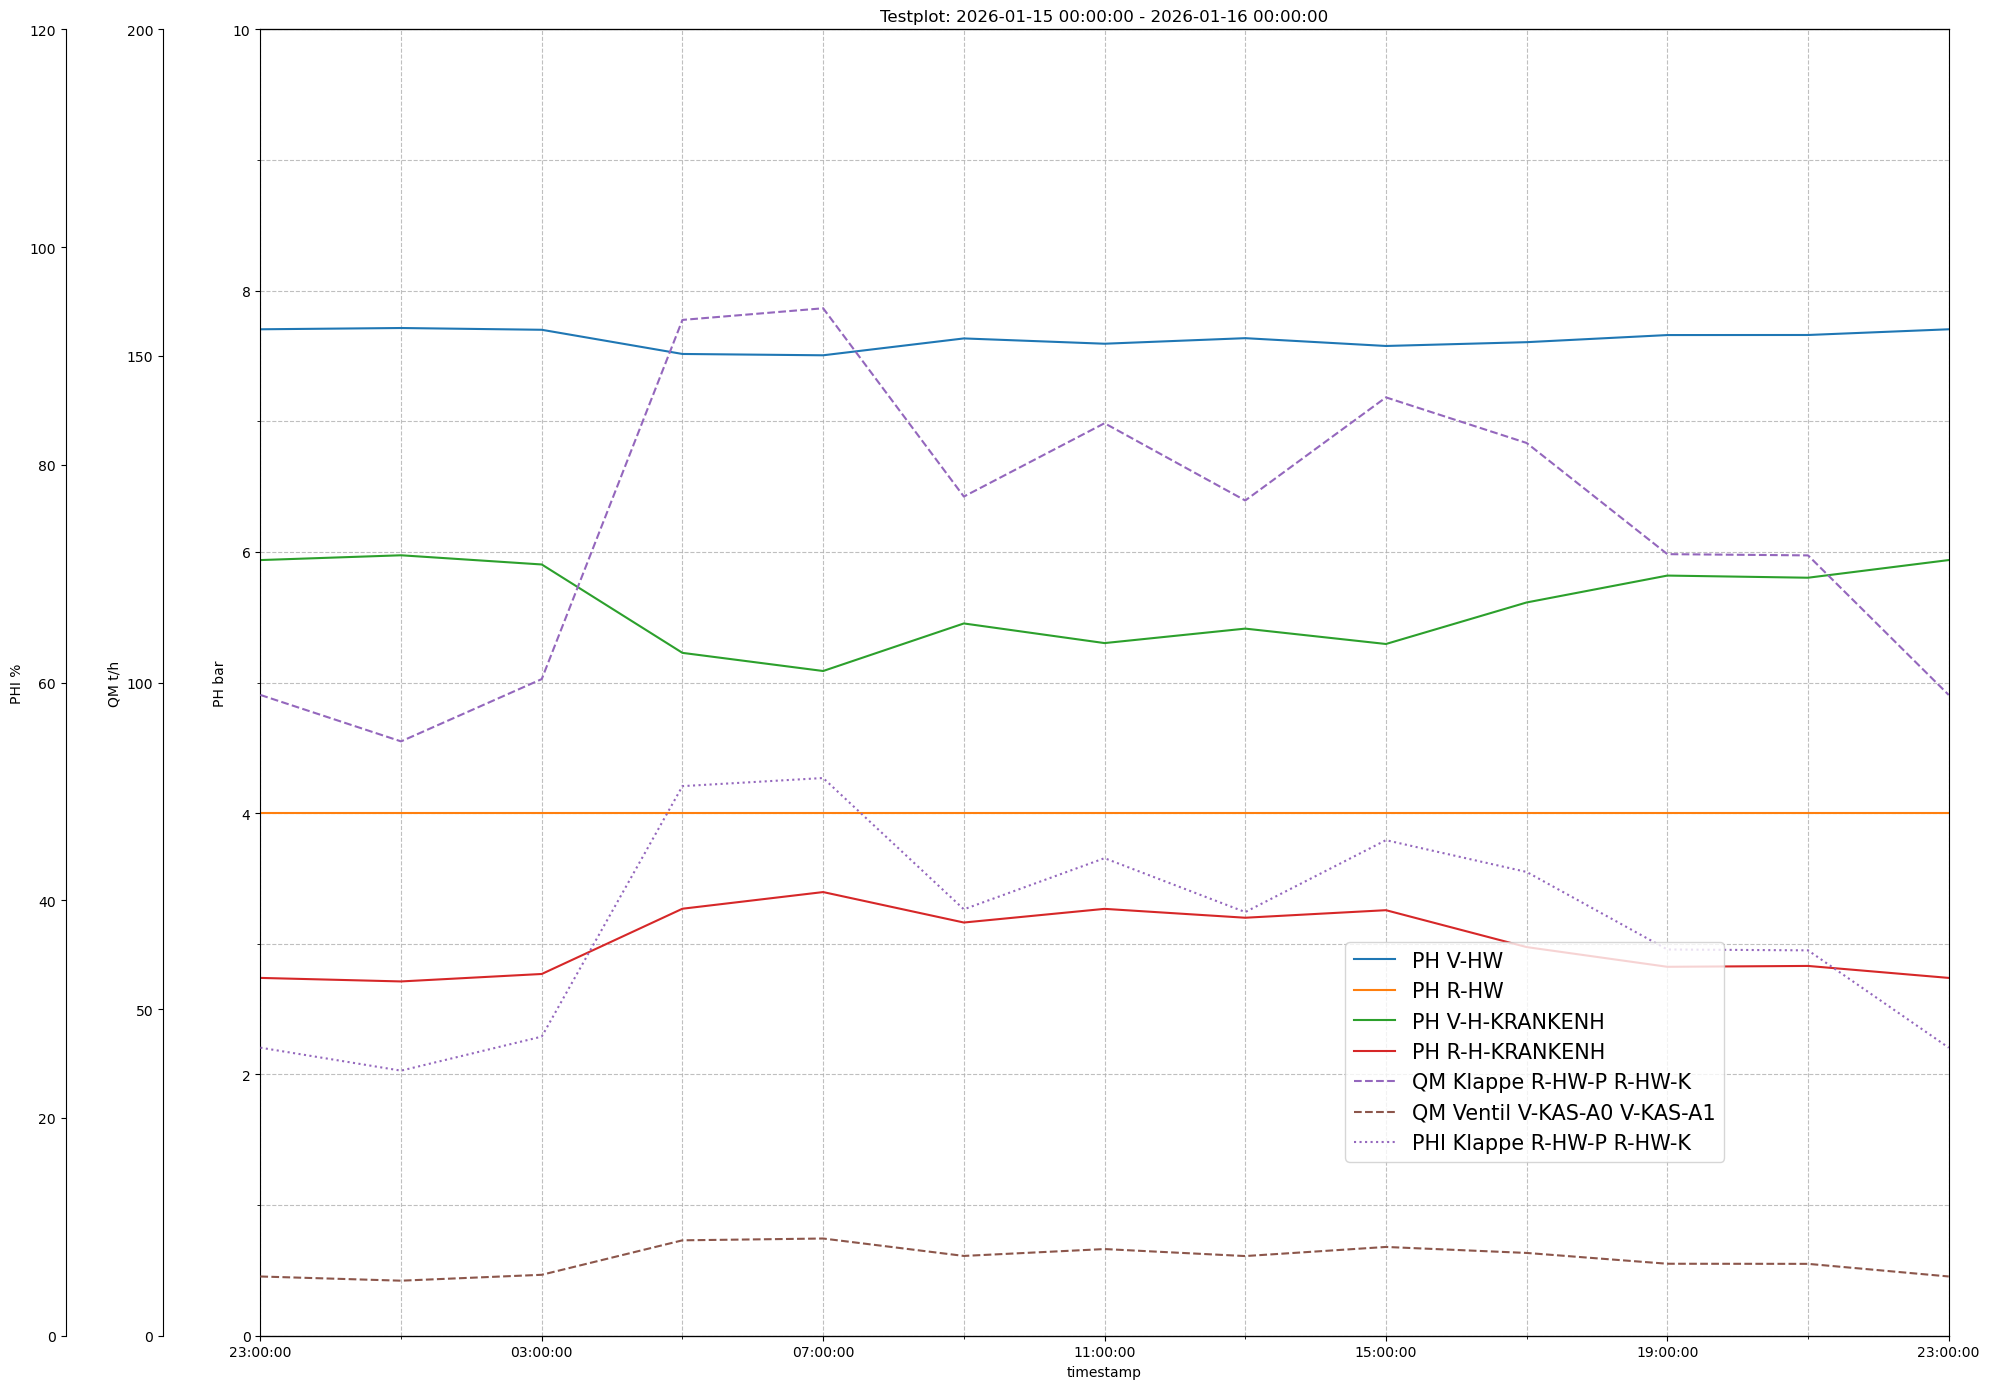

In [22]:
fig, axes, used = s3s.plot_time_curves(
    df=df_results,
    start="2026-01-15 00:00:00.000 +01:00",
    end="2026-01-16 00:00:00.000 +01:00",
    properties=["PH", "QM", "PHI"],
    axis_labels=["PH bar", "QM t/h", "PHI %"],
    ylims=[(0, 10), (0, 200), (0, 120)],
    tks_per_property=[
        nodes_tks,
        vent_tks + valves_tks,
        vent_tks,
    ],

    y_label_ticks=[6, 5, 7],
    y_grid_ticks=11,
    x_label_ticks=7,
    x_grid_ticks=13,

    legend=True,
    legend_in_figure=True,
    legend_loc="upper left",
    legend_coords=(0.67, 0.33),
    legend_fontsize=15,

    title_prefix="Testplot: ",
    show_title=True,

    axis_offset=70,
    linestyles=["-", "--", ":"],
    rotate_xticks=0,

    grid=True,
    grid_style="--",
    grid_alpha=0.8,

    missing="warn",
    logger=None,
)